In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:

df = pd.read_csv(r'laptopData.csv')


In [3]:
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [4]:
df.shape

(1303, 12)

In [5]:
df.columns

Index(['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution',
       'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='str')

In [6]:
df.isnull().sum()

Unnamed: 0          30
Company             30
TypeName            30
Inches              30
ScreenResolution    30
Cpu                 30
Ram                 30
Memory              30
Gpu                 30
OpSys               30
Weight              30
Price               30
dtype: int64

In [7]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [8]:
df


,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080
...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,2 in 1 Convertible,14,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.6400
1299,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.7200
1300,Lenovo,Notebook,14,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.1200
1301,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.9200


In [9]:
from sklearn import impute
from sklearn.impute import SimpleImputer

for col in df.select_dtypes(include=['object']):
    imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
    df[col] = imputer.fit_transform(df[[col]]).ravel()

In [10]:
df.isnull().sum()

Company              0
TypeName             0
Inches               0
ScreenResolution     0
Cpu                  0
Ram                  0
Memory               0
Gpu                  0
OpSys                0
Weight               0
Price               30
dtype: int64

In [11]:
df.dropna(subset=['Price'], inplace=True)

In [12]:
df.isnull().sum().sum()

0

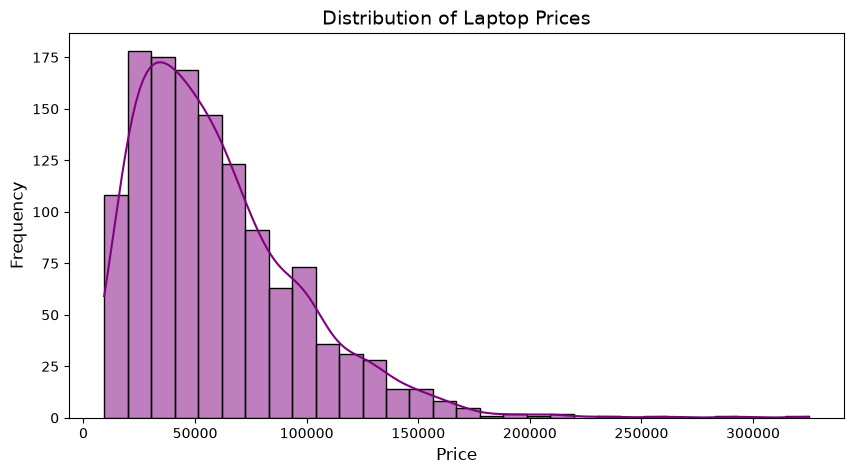

In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Price'], kde=True, color='purple', bins=30)
plt.title('Distribution of Laptop Prices', fontsize=14)
plt.xlabel('Price', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

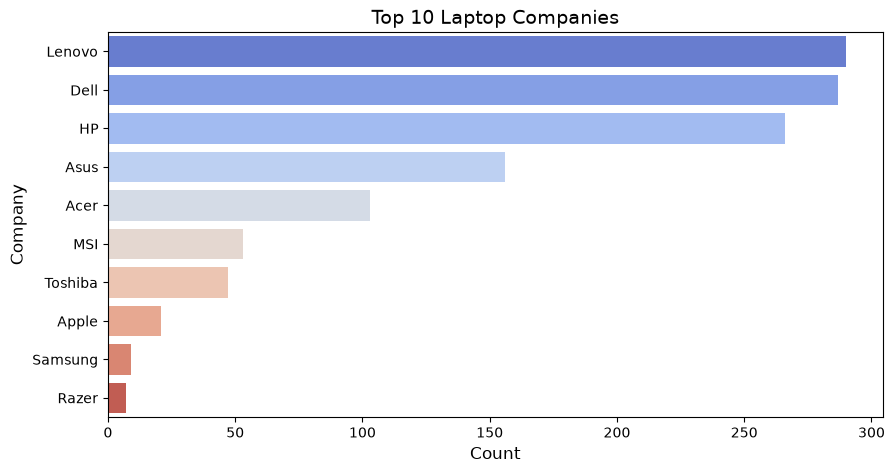

In [14]:
plt.figure(figsize=(10, 5))
top_companies = df['Company'].value_counts().head(10)
sns.barplot(x=top_companies.values, y=top_companies.index, palette='coolwarm')
plt.title('Top 10 Laptop Companies', fontsize=14)
plt.xlabel('Count', fontsize=12)
plt.ylabel('Company', fontsize=12)
plt.show()

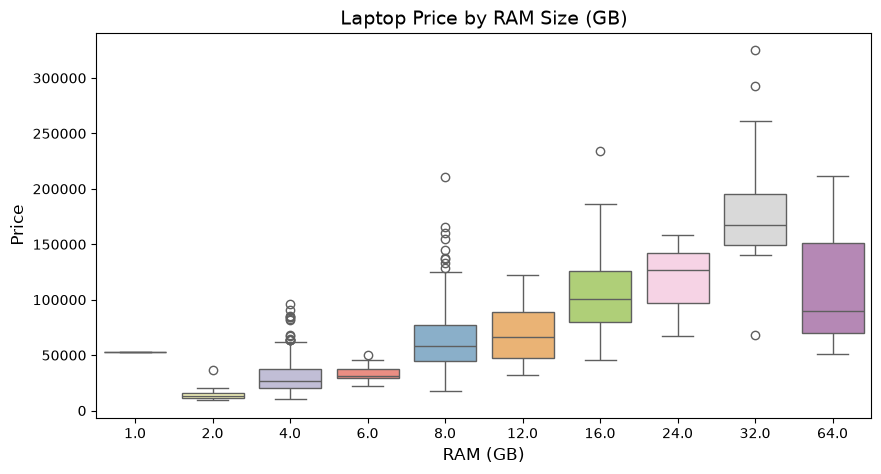

In [15]:
temp_df = df.copy()
temp_df['Ram_GB'] = temp_df['Ram'].str.replace('GB', '').astype(float, errors='ignore')
temp_df['Ram_GB'] = pd.to_numeric(temp_df['Ram_GB'], errors='coerce')

plt.figure(figsize=(10, 5))
sns.boxplot(data=temp_df.sort_values(by='Ram_GB'), x='Ram_GB', y='Price', palette='Set3')
plt.title('Laptop Price by RAM Size (GB)', fontsize=14)
plt.xlabel('RAM (GB)', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.show()

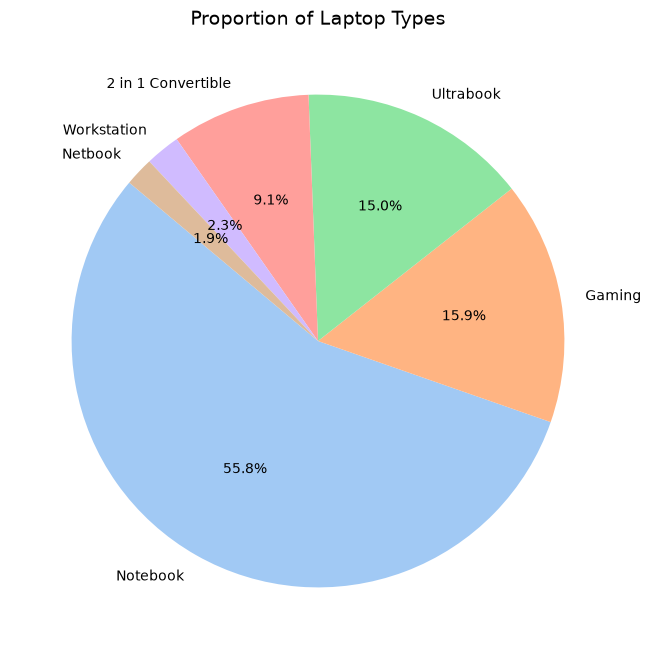

In [16]:
type_counts = df['TypeName'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Proportion of Laptop Types', fontsize=14)
plt.show()

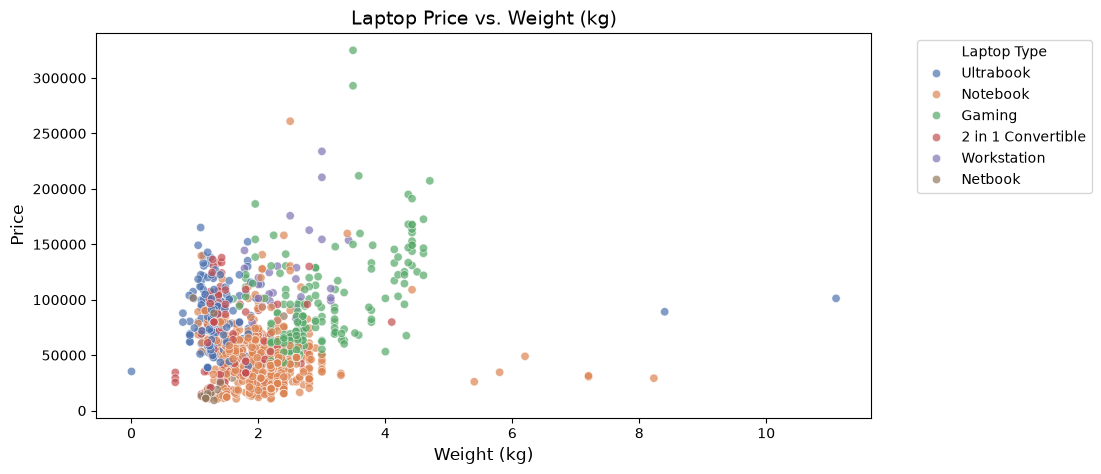

In [17]:
temp_df['Weight_kg'] = temp_df['Weight'].str.replace('kg', '').astype(float, errors='ignore')
temp_df['Weight_kg'] = pd.to_numeric(temp_df['Weight_kg'], errors='coerce')

plt.figure(figsize=(10, 5))
sns.scatterplot(data=temp_df, x='Weight_kg', y='Price', alpha=0.7, hue='TypeName', palette='deep')
plt.title('Laptop Price vs. Weight (kg)', fontsize=14)
plt.xlabel('Weight (kg)', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.legend(title='Laptop Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [18]:

Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


df_cleaned = df[(df['Price'] >= lower_bound) & (df['Price'] <= upper_bound)]

df = df_cleaned

In [19]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
import pandas as pd
import numpy as np

categorical_cols = ['Company', 'TypeName', 'OpSys']
encoder = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
encoded_features = encoder.fit_transform(df[categorical_cols])
encoded_df = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_cols), index=df.index)
df_encoded = df.drop(columns=categorical_cols).join(encoded_df)

df_encoded['Ram'] = df_encoded['Ram'].astype(str).str.replace('GB', '').astype(int)

df_encoded['Weight'] = df_encoded['Weight'].astype(str).str.replace('kg', '')
df_encoded['Weight'] = pd.to_numeric(df_encoded['Weight'], errors='coerce')
if df_encoded['Weight'].isnull().any():
    df_encoded['Weight'] = df_encoded['Weight'].fillna(df_encoded['Weight'].median())

label_cols = ['ScreenResolution', 'Cpu', 'Memory', 'Gpu']
le = LabelEncoder()
for col in label_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))


df=df_encoded

In [20]:
df

,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,Weight,Price,Company_Apple,Company_Asus,...,TypeName_Ultrabook,TypeName_Workstation,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,13.3,23,65,8,4,56,1.37,71378.6832,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,13.3,1,63,8,2,49,1.34,47895.5232,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,15.6,8,74,8,14,51,1.86,30636.0000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,15.4,25,85,16,27,8,1.83,135195.3360,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,13.3,23,67,8,14,57,1.37,96095.8080,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,14,13,88,4,4,45,1.80,33992.6400,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1299,13.3,19,88,16,27,45,1.30,79866.7200,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1300,14,0,34,2,32,38,1.50,12201.1200,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1301,15.6,0,88,6,10,19,2.19,40705.9200,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [21]:

df['Inches'] = pd.to_numeric(df['Inches'], errors='coerce')
if df['Inches'].isnull().any():
    df['Inches'] = df['Inches'].fillna(df['Inches'].median())



In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X = df.drop(columns=['Price'])
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=100
)

my_scaler = MinMaxScaler(feature_range=(0, 1))

X_train = my_scaler.fit_transform(X_train)

X_test = my_scaler.transform(X_test)


In [23]:
from tqdm import tqdm

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor


In [24]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, metric='minkowski', p=1),  # minkowski, euclidean, manhattan
    "SVM": SVR(kernel='linear', C=100, gamma=1),  # kernel='rbf' / 'poly', degree=4 / 'sigmoid'
    "Decision Tree": DecisionTreeRegressor(criterion='squared_error', max_depth=10),
    "Random Forest": RandomForestRegressor(n_estimators=50, criterion='squared_error', max_depth=10),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error', max_depth=10),
                                n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
}


In [25]:
# Metrics function (same as the Ames notebook)
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2


## 3) Train every model (no per-model printing)

In [26]:
errors = {}
fitted_models = {}

for model_name, model in tqdm(models.items()):
    model.fit(X_train, y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }
    fitted_models[model_name] = model


  0%|          | 0/15 [00:00<?, ?it/s]

 13%|█▎        | 2/15 [00:00<00:01, 11.77it/s]

 27%|██▋       | 4/15 [00:06<00:20,  1.87s/it]

 33%|███▎      | 5/15 [00:07<00:16,  1.67s/it]

 40%|████      | 6/15 [00:07<00:10,  1.21s/it]

 47%|████▋     | 7/15 [00:09<00:10,  1.29s/it]

... (6 outputs left out)

 93%|█████████▎| 14/15 [00:57<00:06,  6.43s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003359 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 339
[LightGBM] [Info] Number of data points in the train set: 996, number of used features: 23
[LightGBM] [Info] Start training from score 56375.762601


100%|██████████| 15/15 [00:57<00:00,  4.64s/it]

100%|██████████| 15/15 [00:57<00:00,  3.85s/it]

In [27]:
# Individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Simple averaging
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)

for name, mdl in [("Voting", model1), ("Simple Voting", model2), ("Weighted Voting", model3)]:
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(mdl, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(mdl, X_test, y_test)

    errors[name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train,
        "R2 Test": R2_Test
    }
    fitted_models[name] = mdl


In [28]:
# Base models for stacking
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# Meta-model
meta_regressor = XGBRegressor()

stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)

stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
    "MAE Train": MAE_Train,
    "MAE Test": MAE_Test,
    "MSE Train": MSE_Train,
    "MSE Test": MSE_Test,
    "RMSE Train": RMSE_Train,
    "RMSE Test": RMSE_Test,
    "R2 Train": R2_Train,
    "R2 Test": R2_Test
}
fitted_models["Stacking"] = stacking_regressor


## 4) Comparison table (all models)

In [29]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test", ascending=False)
errors_df


,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
HistGradientBoosting,4482.773500,9046.295606,4.163742e+07,1.753055e+08,6452.706282,13240.298673,0.957278,0.848800
LightGBM,4596.841492,9183.423030,4.395361e+07,1.777290e+08,6629.751989,13331.504118,0.954902,0.846710
XGBoost,3896.761470,9108.467422,3.255558e+07,1.863908e+08,5705.749848,13652.501962,0.966597,0.839239
GradientBoosting,7692.827288,9838.758344,1.080628e+08,1.946325e+08,10395.325074,13951.075747,0.889123,0.832131
Stacking,4918.557090,9741.200764,6.414586e+07,2.058720e+08,8009.110825,14348.238997,0.934184,0.822437
Bagging,5239.404514,9904.604211,5.509680e+07,2.120748e+08,7422.721653,14562.789264,0.943468,0.817087
Random Forest,5132.639253,10064.960637,5.239423e+07,2.134449e+08,7238.385933,14609.752243,0.946241,0.815906
CatBoost,7578.704061,10340.094009,1.051967e+08,2.181476e+08,10256.545164,14769.820667,0.892064,0.811849
ExtraTrees,142.728347,9969.791752,7.569861e+05,2.192564e+08,870.049501,14807.309309,0.999223,0.810893
Simple Voting,4936.929802,10639.245956,4.694363e+07,2.489434e+08,6851.542376,15777.940677,0.951834,0.785288


In [30]:
best_model_name = errors_df.index[0]
best_model = fitted_models[best_model_name]

print("=" * 65)
print(f"Best Model: {best_model_name}")
print("=" * 65)
print(f"{'Metric':<8}{'Train':>18}{'Test':>18}")
print("-" * 65)
for metric in ["MAE", "MSE", "RMSE", "R2"]:
    print(f"{metric:<8}"
          f"{errors_df.loc[best_model_name, metric + ' Train']:>18.4f}"
          f"{errors_df.loc[best_model_name, metric + ' Test']:>18.4f}")
print("=" * 65)


Best Model: HistGradientBoosting
Metric               Train              Test
-----------------------------------------------------------------
MAE              4482.7735         9046.2956
MSE          41637418.3638    175305508.9395
RMSE             6452.7063        13240.2987
R2                  0.9573            0.8488


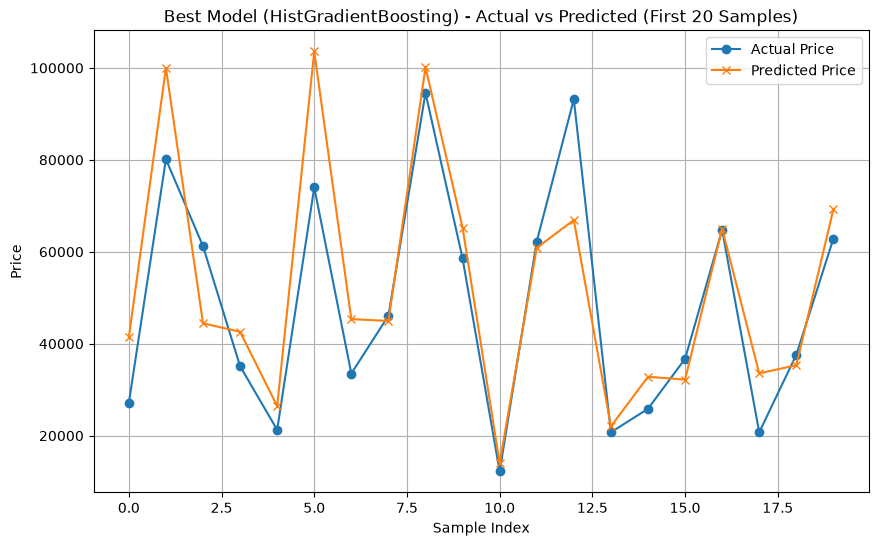

In [31]:
# Actual vs Predicted for the best model only (first 20 test samples)
y_test_plot = y_test.values[:20]
y_pred_plot = best_model.predict(X_test[:20])

plt.figure(figsize=(10, 6))
plt.plot(range(20), y_test_plot, label='Actual Price', marker='o')
plt.plot(range(20), y_pred_plot, label='Predicted Price', marker='x')
plt.xlabel('Sample Index')
plt.ylabel('Price')
plt.title(f'Best Model ({best_model_name}) - Actual vs Predicted (First 20 Samples)')
plt.legend()
plt.grid()
plt.show()


## 6)comparison charts

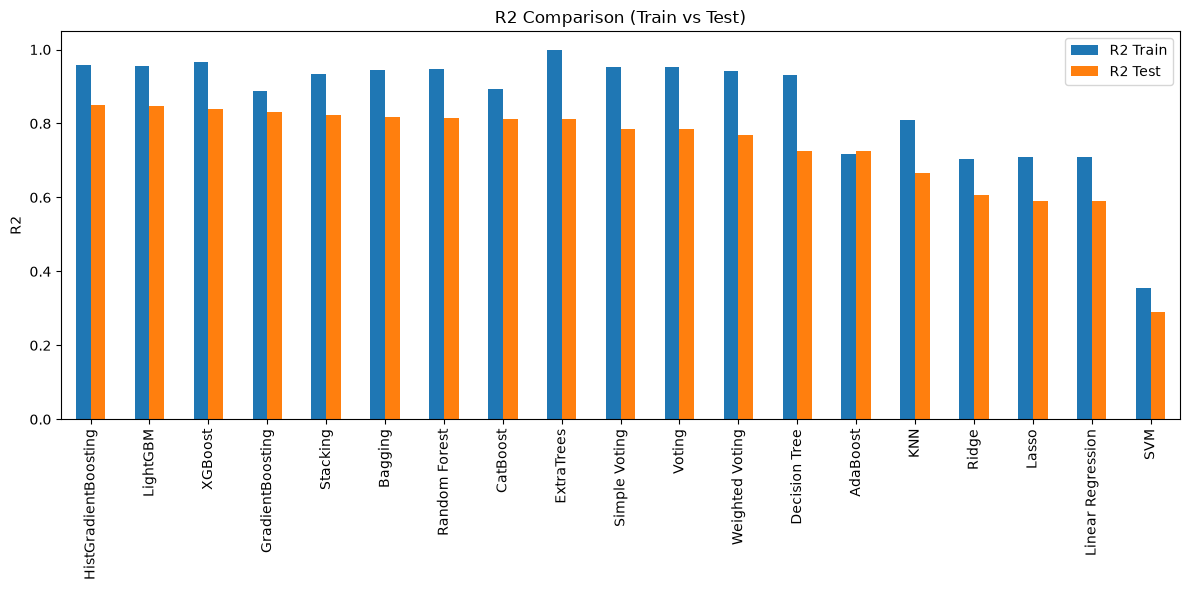

In [32]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12, 6))
plt.title('R2 Comparison (Train vs Test)')
plt.ylabel('R2')
plt.tight_layout()
plt.show()


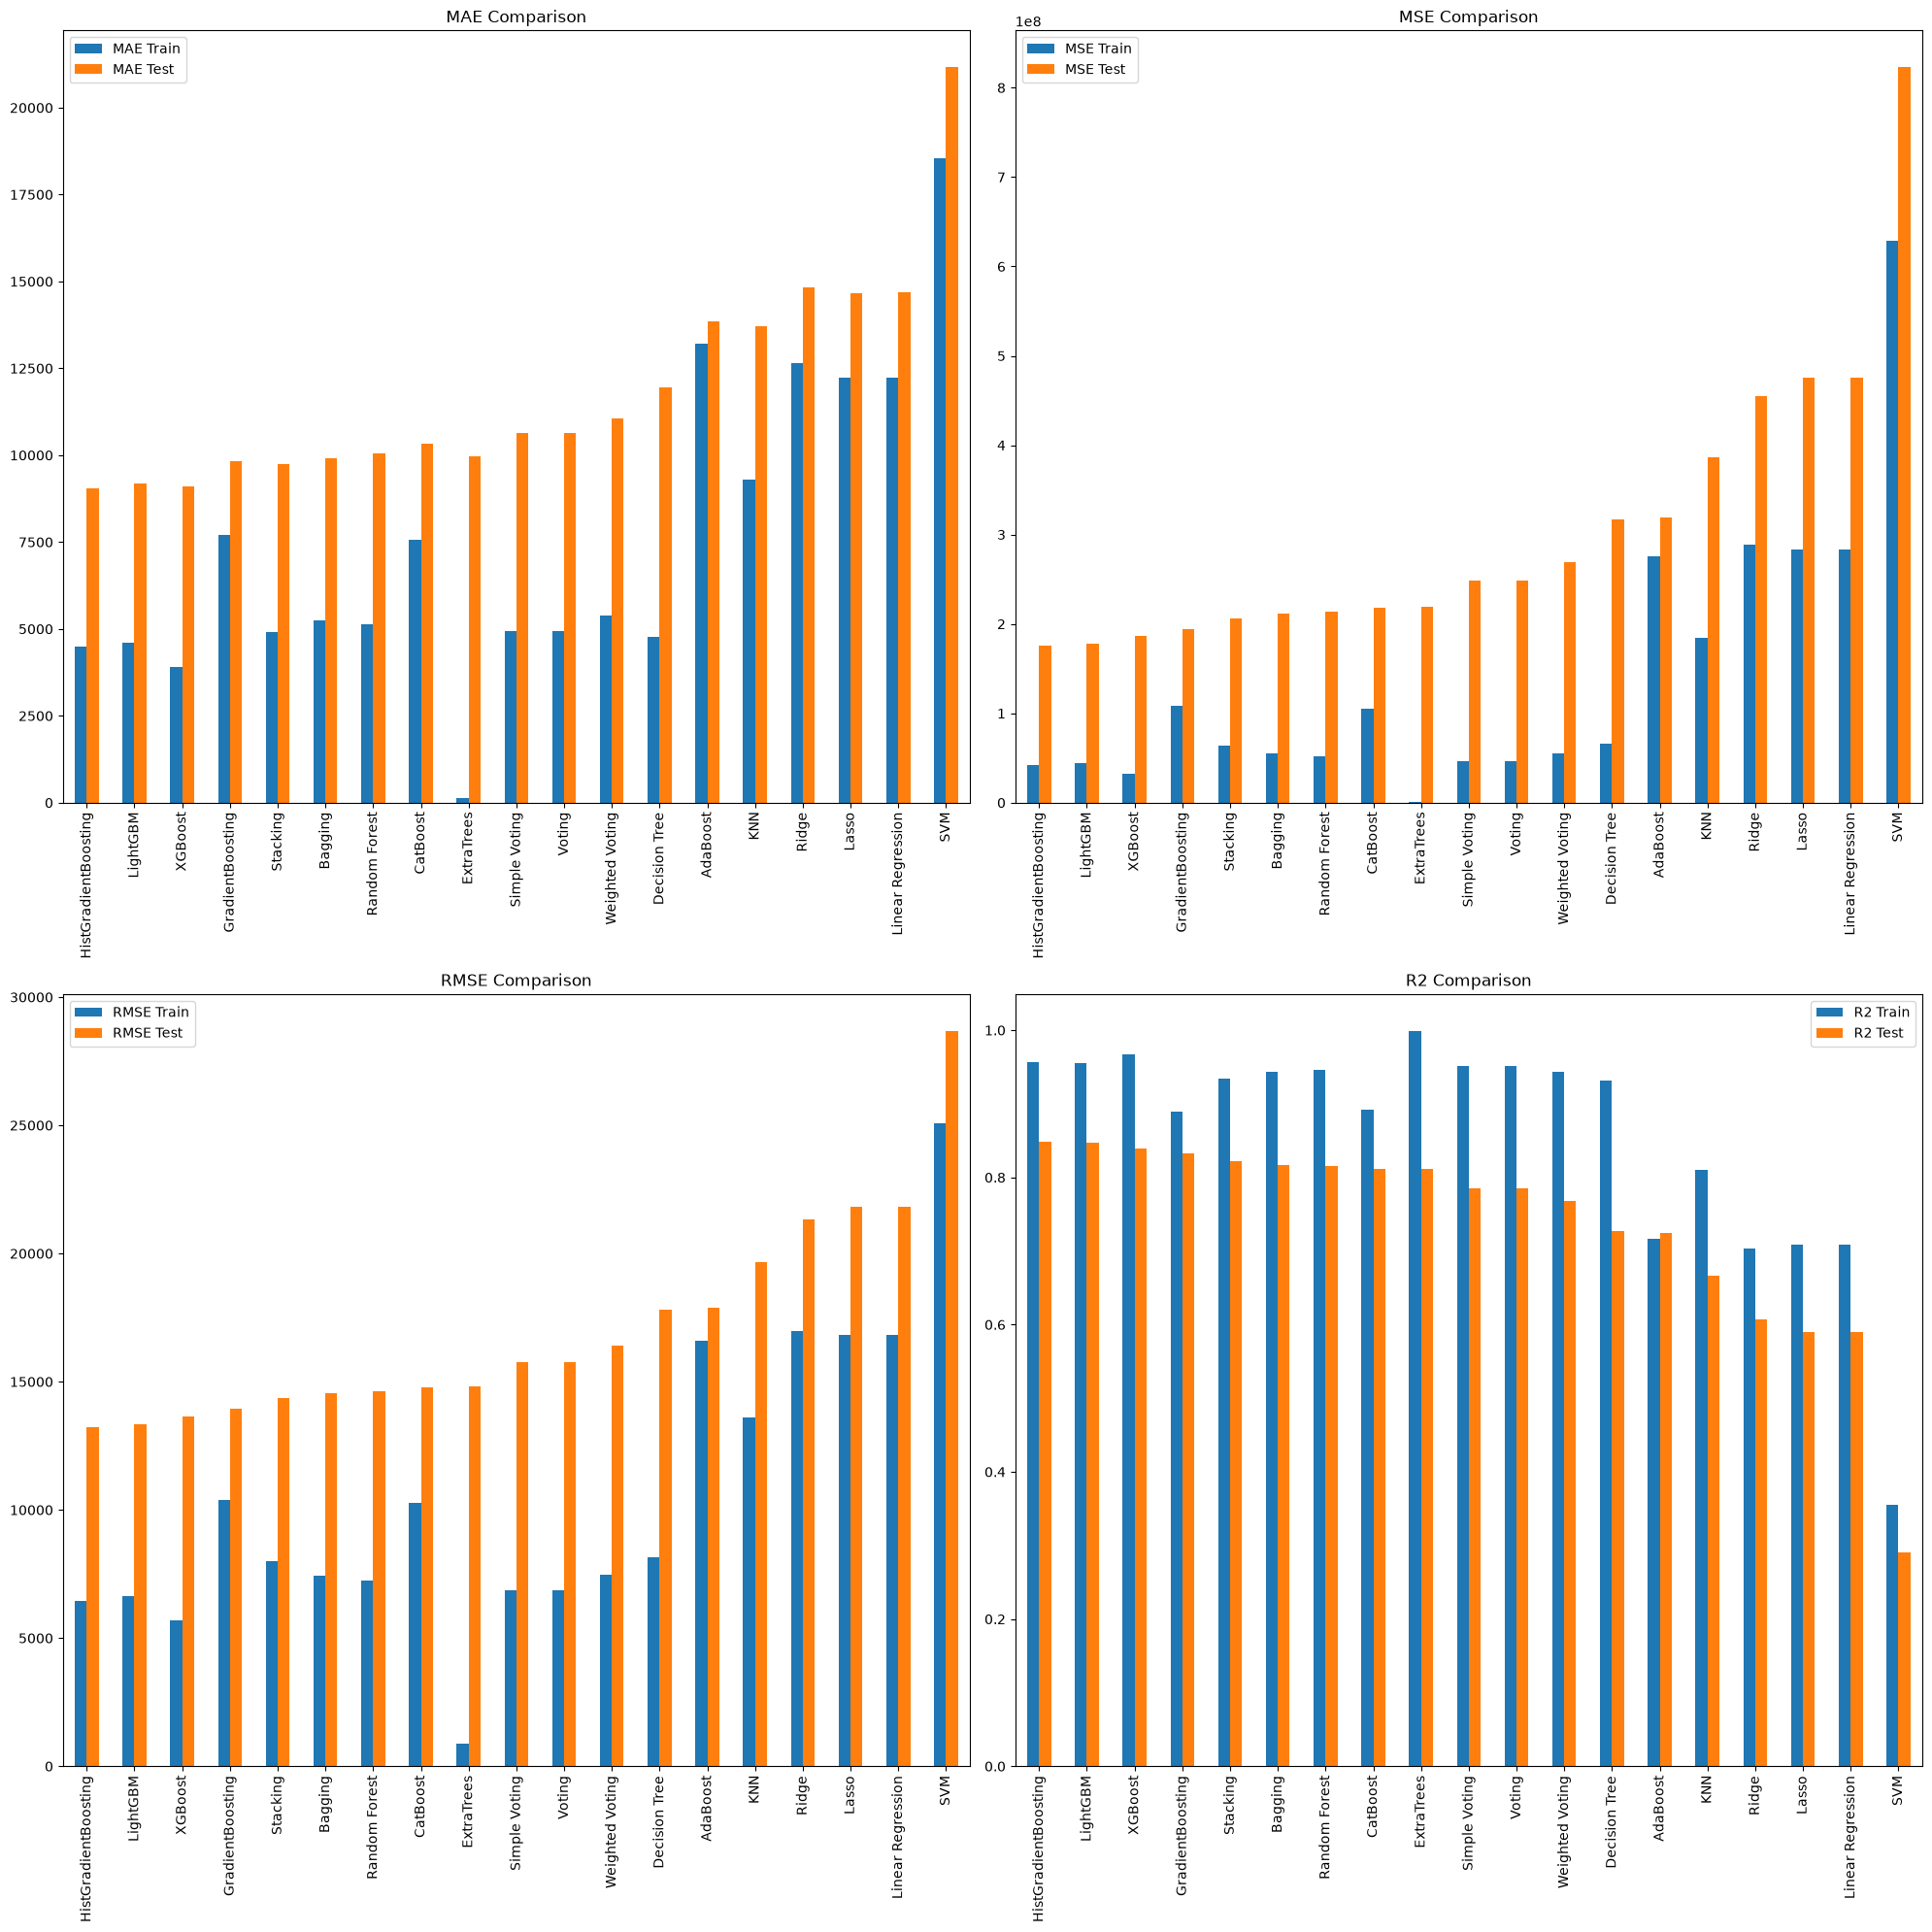

In [33]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20, 20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i + 1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()
